# Un proyecto de punta a punta

Los notebooks anteriores se concentran en una pieza a la vez. Este recorre un proyecto completo, desde el archivo de datos hasta un modelo guardado que otra persona puede cargar y usar. Junta lo que enseñan varias lecturas del módulo:

- **El tutorial *60 Minute Blitz* de PyTorch** y el libro ***Deep Learning with PyTorch*** (Manning): el modelo como clase `nn.Module`, los datos como `Dataset` y `DataLoader`, el ciclo de entrenamiento separado en funciones, `model.train()` y `model.eval()`, y guardar y cargar con `state_dict`.
- **La lista de pasos de Aurélien Géron** en *Hands-On Machine Learning*: plantear el problema y la métrica, separar la prueba antes de mirar los datos, preparar, comparar modelos, evaluar una sola vez, analizar los errores.
- **Las *Rules of Machine Learning* de Google**: empezar con una línea base sin machine learning, primero un modelo simple, y cuidar que el modelo se use exactamente como se entrenó.
- **La guía de MLOps de Google Cloud**: validar los datos y guardar junto al modelo todo lo necesario para reproducirlo.

**Contenido**

1. Preparación
2. El problema y la métrica
3. Los datos llegan en un archivo
4. Validar antes de usar
5. Separar entrenamiento, validación y prueba
6. Líneas base: sin machine learning y con un modelo lineal
7. `Dataset` y `DataLoader`
8. El modelo y el ciclo de entrenamiento
9. Guardar el mejor modelo
10. Evaluar una sola vez en la prueba
11. Analizar los errores
12. Usar el modelo guardado
13. Resumen y ejercicios

## 1. Preparación

In [1]:
import copy
import math
import tempfile
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("Versión de PyTorch:", torch.__version__)

CARPETA = Path(tempfile.mkdtemp())     # una carpeta temporal para el archivo de datos y el modelo

Versión de PyTorch: 2.11.0+cpu


## 2. El problema y la métrica

Una empresa eléctrica quiere estimar el **consumo mensual** de una casa (en kWh) a partir de cuatro datos: su superficie en m², cuántas personas viven en ella, la temperatura media del mes y si tiene aire acondicionado. Con esa estimación puede avisar a un cliente cuando su consumo real se sale de lo esperado.

Es un problema de **regresión**. Antes de entrenar nada hay que decidir cómo se va a medir el éxito (la regla 2 de Google: diseñar las métricas primero). Usamos el **error absoluto medio** (MAE): el promedio de $|\hat{y} - y|$, en kWh. Se entiende sin explicación ("el modelo se equivoca en promedio por 20 kWh") y no lo dominan unos pocos errores grandes, como pasaría con el error cuadrático. Para entrenar usamos MSE, que tiene mejores gradientes; para decidir y para informar, MAE.

## 3. Los datos llegan en un archivo

Los datos de este notebook son sintéticos: los generamos con una fórmula conocida y algo de ruido, para poder comprobar al final qué tan cerca quedó el modelo de lo mejor posible. Pero los tratamos como datos reales: se escriben a un archivo CSV y desde ahí se leen, sin mirar la fórmula.

La fórmula tiene una parte que un modelo lineal no puede representar. El consumo sube cuando hace frío (calefacción) y también cuando hace calor, pero solo en las casas con aire acondicionado. Y como los datos reales nunca llegan limpios, agregamos algunos errores de registro: temperaturas que faltan, superficies con el signo cambiado y casas con 0 personas.

In [2]:
def generar_consumos(n=2000, semilla=0):
    generador = torch.Generator().manual_seed(semilla)
    superficie = 40 + 210 * torch.rand(n, generator=generador)
    personas = torch.randint(1, 7, (n,), generator=generador).float()
    temperatura = -5 + 40 * torch.rand(n, generator=generador)
    aire = (torch.rand(n, generator=generador) < 0.4).float()

    calefaccion = 0.06 * superficie * torch.relu(15 - temperatura)
    refrigeracion = 0.1 * aire * superficie * torch.relu(temperatura - 22)
    consumo = 60 + 0.9 * superficie + 35 * personas + calefaccion + refrigeracion
    consumo = consumo + 25 * torch.randn(n, generator=generador)          # ruido: lo que el modelo no puede saber

    datos = torch.stack([superficie, personas, temperatura, aire, consumo], dim=1)

    # Errores de registro
    filas = torch.randperm(n, generator=generador)
    datos[filas[:30], 2] = float("nan")       # temperatura faltante
    datos[filas[30:45], 0] *= -1              # superficie con el signo cambiado
    datos[filas[45:55], 1] = 0                # casas con 0 personas
    return datos


COLUMNAS = ["superficie_m2", "personas", "temperatura_c", "aire_acondicionado", "consumo_kwh"]
archivo = CARPETA / "consumos.csv"
np.savetxt(archivo, generar_consumos().numpy(), delimiter=",", header=",".join(COLUMNAS), comments="", fmt="%.3f")

print(archivo.name)
print("".join(archivo.read_text().splitlines(keepends=True)[:6]))

consumos.csv
superficie_m2,personas,temperatura_c,aire_acondicionado,consumo_kwh
144.214,6.000,24.949,0.000,360.017
201.327,2.000,9.696,1.000,400.509
58.580,1.000,nan,1.000,201.000
67.726,1.000,-2.478,0.000,263.196
104.559,1.000,32.117,1.000,297.557



Desde aquí en adelante solo sabemos lo que dice el archivo. Lo leemos con NumPy, que convierte las celdas vacías o con `nan` en `NaN`, y pasamos a un tensor `float32` (`00-fundamentos/02_tensores_a_fondo`, sección 2):

In [3]:
crudo = torch.from_numpy(np.genfromtxt(archivo, delimiter=",", skip_header=1)).float()
print("forma:", crudo.shape, "  dtype:", crudo.dtype)

forma: torch.Size([2000, 5])   dtype: torch.float32


## 4. Validar antes de usar

Un modelo entrenado con datos corruptos no da error: aprende de los datos corruptos. Por eso, antes de entrenar, se comprueba que cada columna cumpla lo que se espera de ella. Las reglas salen del conocimiento del problema, no de los datos. La guía de MLOps de Google pone la validación de datos como un paso fijo del pipeline, porque en producción los datos nuevos llegan solos y nadie los mira.

In [4]:
REGLAS = {
    "superficie_m2": (20, 1000),
    "personas": (1, 12),
    "temperatura_c": (-30, 50),
    "aire_acondicionado": (0, 1),
    "consumo_kwh": (0, 5000),
}


def validar(datos, columnas):
    validas = torch.ones(len(datos), dtype=torch.bool)
    for j, nombre in enumerate(columnas):
        minimo, maximo = REGLAS[nombre]
        columna = datos[:, j]
        faltantes = torch.isnan(columna)
        fuera = ~faltantes & ((columna < minimo) | (columna > maximo))
        if faltantes.any() or fuera.any():
            print(f"  {nombre:20s} {faltantes.sum().item():3d} faltantes   {fuera.sum().item():3d} fuera de [{minimo}, {maximo}]")
        validas &= ~faltantes & ~fuera
    return validas


print("problemas encontrados:")
validas = validar(crudo, COLUMNAS)
datos = crudo[validas]
print(f"\nfilas válidas: {validas.sum().item()} de {len(crudo)}")

problemas encontrados:
  superficie_m2          0 faltantes    15 fuera de [20, 1000]
  personas               0 faltantes    10 fuera de [1, 12]
  temperatura_c         30 faltantes     0 fuera de [-30, 50]

filas válidas: 1945 de 2000


La validación encontró los tres tipos de error que pusimos. Aquí simplemente descartamos esas filas, porque son pocas. En un proyecto real conviene además averiguar de dónde vienen: un signo cambiado en la superficie suele ser un error del sistema que registra los datos, y va a seguir pasando.

## 5. Separar entrenamiento, validación y prueba

Géron insiste en apartar el conjunto de prueba **antes** de explorar los datos, para que nada de lo que se decida dependa de él. Usamos tres conjuntos:

- **Entrenamiento** (60%): el único que ve el optimizador.
- **Validación** (20%): para comparar modelos y decidir cuándo parar de entrenar.
- **Prueba** (20%): se usa una sola vez, al final, para informar el desempeño.

La separación es al azar, con semilla fija para que sea reproducible.

In [5]:
generador = torch.Generator().manual_seed(42)
orden = torch.randperm(len(datos), generator=generador)
n_entrenamiento = int(0.6 * len(datos))
n_validacion = int(0.2 * len(datos))

entrenamiento = datos[orden[:n_entrenamiento]]
validacion = datos[orden[n_entrenamiento:n_entrenamiento + n_validacion]]
prueba = datos[orden[n_entrenamiento + n_validacion:]]


def separar(tabla):
    return tabla[:, :4], tabla[:, 4]          # entradas y consumo


X_ent, y_ent = separar(entrenamiento)
X_val, y_val = separar(validacion)
X_pru, y_pru = separar(prueba)
print(f"entrenamiento {len(X_ent)}   validación {len(X_val)}   prueba {len(X_pru)}")

entrenamiento 1167   validación 389   prueba 389


Con los datos separados ya se pueden explorar, mirando solo el entrenamiento. El consumo contra la temperatura muestra la forma de U, y que la subida con calor es solo de las casas con aire acondicionado:

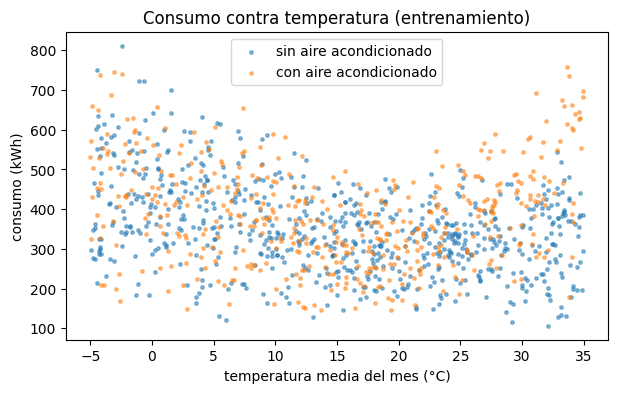

In [6]:
con_aire = X_ent[:, 3] == 1
plt.figure(figsize=(7, 4))
plt.scatter(X_ent[~con_aire, 2], y_ent[~con_aire], s=6, alpha=0.5, label="sin aire acondicionado")
plt.scatter(X_ent[con_aire, 2], y_ent[con_aire], s=6, alpha=0.5, label="con aire acondicionado")
plt.xlabel("temperatura media del mes (°C)")
plt.ylabel("consumo (kWh)")
plt.title("Consumo contra temperatura (entrenamiento)")
plt.legend()
plt.show()

## 6. Líneas base: sin machine learning y con un modelo lineal

La primera regla de Google dice que no hay que tener miedo de lanzar un producto sin machine learning. Antes de una red, conviene saber cuánto se logra sin ella, porque esa es la vara contra la que se mide todo lo demás. Probamos tres cosas, de menos a más:

1. **Predecir siempre la media** del consumo de entrenamiento.
2. **Una regla de negocio**: kWh por m² promedio, multiplicado por la superficie de la casa.
3. **Una regresión lineal** con las cuatro entradas, resuelta con mínimos cuadrados (las ecuaciones normales de `03-optimalidad`).

In [7]:
def mae(prediccion, real):
    return (prediccion - real).abs().mean().item()


# 1. La media
media = y_ent.mean()

# 2. kWh por m² promedio
kwh_por_m2 = (y_ent / X_ent[:, 0]).mean()

# 3. Regresión lineal: columna de unos para el término constante
def con_unos(X):
    return torch.cat([X, torch.ones(len(X), 1)], dim=1)


coeficientes = torch.linalg.lstsq(con_unos(X_ent), y_ent.unsqueeze(1)).solution.squeeze(1)

lineas_base = {
    "la media": lambda X: media.expand(len(X)),
    "kWh por m²": lambda X: kwh_por_m2 * X[:, 0],
    "regresión lineal": lambda X: con_unos(X) @ coeficientes,
}
for nombre, predecir in lineas_base.items():
    print(f"{nombre:18s} MAE validación: {mae(predecir(X_val), y_val):6.1f} kWh")

la media           MAE validación:   95.0 kWh
kWh por m²         MAE validación:  108.6 kWh
regresión lineal   MAE validación:   42.7 kWh


La media se equivoca en 95 kWh por casa. La regla de kWh por m² es **peor** que la media: la superficie importa, pero el consumo no es proporcional a ella, porque una parte no crece con los m² (por ejemplo, la que depende de cuántas personas viven en la casa). Las intuiciones de negocio también hay que medirlas. La regresión lineal baja a 43 kWh, menos de la mitad que la media.

Esa es la vara: para justificar su complejidad, la red tiene que hacerlo claramente mejor que 43 kWh.

## 7. `Dataset` y `DataLoader`

Para la red usamos las herramientas estándar de PyTorch para datos. Un `Dataset` es cualquier objeto con dos métodos: `__len__` (cuántos ejemplos hay) y `__getitem__` (el ejemplo número `i`). Un `DataLoader` lo recorre en mini-batches, mezclando el orden en cada época si se le pide (`02-descenso-de-gradiente/02_sgd_y_minibatches`).

La red trabaja mejor con entradas y salidas en escalas parecidas (`02-descenso-de-gradiente/01_descenso_de_gradiente`), así que el `Dataset` normaliza. Un detalle importante: la media y la desviación se calculan **solo con el entrenamiento**. Si se calcularan con todos los datos, información de la validación y la prueba se filtraría al entrenamiento, y sus errores dejarían de medir el desempeño en datos nuevos.

In [8]:
estadisticas = {
    "media_x": X_ent.mean(dim=0),
    "desv_x": X_ent.std(dim=0),
    "media_y": y_ent.mean(),
    "desv_y": y_ent.std(),
}


class Consumos(Dataset):
    def __init__(self, X, y, estadisticas):
        self.X = (X - estadisticas["media_x"]) / estadisticas["desv_x"]
        self.y = (y - estadisticas["media_y"]) / estadisticas["desv_y"]

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        return self.X[i], self.y[i]


datos_entrenamiento = Consumos(X_ent, y_ent, estadisticas)
cargador = DataLoader(datos_entrenamiento, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(0))

xb, yb = next(iter(cargador))
print("ejemplos:", len(datos_entrenamiento), "  lotes por época:", len(cargador))
print("un lote:", xb.shape, yb.shape)

ejemplos: 1167   lotes por época: 19
un lote: torch.Size([64, 4]) torch.Size([64])


## 8. El modelo y el ciclo de entrenamiento

El modelo es una clase que hereda de `nn.Module`, como en el *60 Minute Blitz*: las capas se declaran en `__init__` y el cálculo va en `forward`. Dos capas ocultas de 64 neuronas con ReLU, y una salida.

El ciclo de entrenamiento se separa en dos funciones, que es como lo organiza el libro de Manning: una que entrena una época y otra que mide el MAE en kWh. La segunda deshace la normalización de la salida, porque la métrica tiene que estar en las unidades del problema.

`modelo.train()` y `modelo.eval()` cambian el modo del modelo. Con estas capas no hay diferencia, pero capas como `Dropout` y `BatchNorm` se comportan distinto al entrenar y al predecir. Llamarlas siempre es la costumbre que evita un error difícil de encontrar cuando el modelo crezca.

In [9]:
class ModeloConsumo(nn.Module):
    def __init__(self, entradas=4, ocultas=64):
        super().__init__()
        self.red = nn.Sequential(
            nn.Linear(entradas, ocultas), nn.ReLU(),
            nn.Linear(ocultas, ocultas), nn.ReLU(),
            nn.Linear(ocultas, 1),
        )

    def forward(self, x):
        return self.red(x).squeeze(1)       # [lote, 1] -> [lote], la misma forma que la etiqueta


def entrenar_una_epoca(modelo, cargador, optimizador, criterio):
    modelo.train()
    total = 0.0
    for xb, yb in cargador:
        perdida = criterio(modelo(xb), yb)
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()
        total += perdida.item() * len(xb)
    return total / len(cargador.dataset)


def predecir_kwh(modelo, X, estadisticas):
    modelo.eval()
    with torch.no_grad():
        normalizado = (X - estadisticas["media_x"]) / estadisticas["desv_x"]
        return modelo(normalizado) * estadisticas["desv_y"] + estadisticas["media_y"]

El `squeeze(1)` en `forward` no es un detalle: sin él, la salida tendría forma `[64, 1]` y la etiqueta `[64]`, y la pérdida calcularía las 64 × 64 diferencias en vez de 64 (el error silencioso de `00-fundamentos/02_tensores_a_fondo`, sección 8).

Entrenamos 150 épocas con Adam, y al final de cada una medimos el MAE en validación:

In [10]:
torch.manual_seed(0)
modelo = ModeloConsumo()
optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)
criterio = nn.MSELoss()

historia = {"perdida": [], "mae_validacion": []}
mejor_mae, mejor_epoca, mejor_estado = float("inf"), None, None

for epoca in range(150):
    perdida = entrenar_una_epoca(modelo, cargador, optimizador, criterio)
    mae_val = mae(predecir_kwh(modelo, X_val, estadisticas), y_val)
    historia["perdida"].append(perdida)
    historia["mae_validacion"].append(mae_val)

    if mae_val < mejor_mae:
        mejor_mae, mejor_epoca = mae_val, epoca
        mejor_estado = copy.deepcopy(modelo.state_dict())

    if epoca % 25 == 0 or epoca == 149:
        print(f"época {epoca:3d}   pérdida {perdida:.4f}   MAE validación {mae_val:6.2f} kWh")

print(f"\nmejor época: {mejor_epoca}, con MAE de validación {mejor_mae:.2f} kWh")

época   0   pérdida 0.7567   MAE validación  62.54 kWh


época  25   pérdida 0.0460   MAE validación  22.29 kWh


época  50   pérdida 0.0428   MAE validación  20.93 kWh


época  75   pérdida 0.0405   MAE validación  20.74 kWh


época 100   pérdida 0.0401   MAE validación  20.75 kWh


época 125   pérdida 0.0389   MAE validación  21.52 kWh


época 149   pérdida 0.0410   MAE validación  20.82 kWh

mejor época: 134, con MAE de validación 20.23 kWh


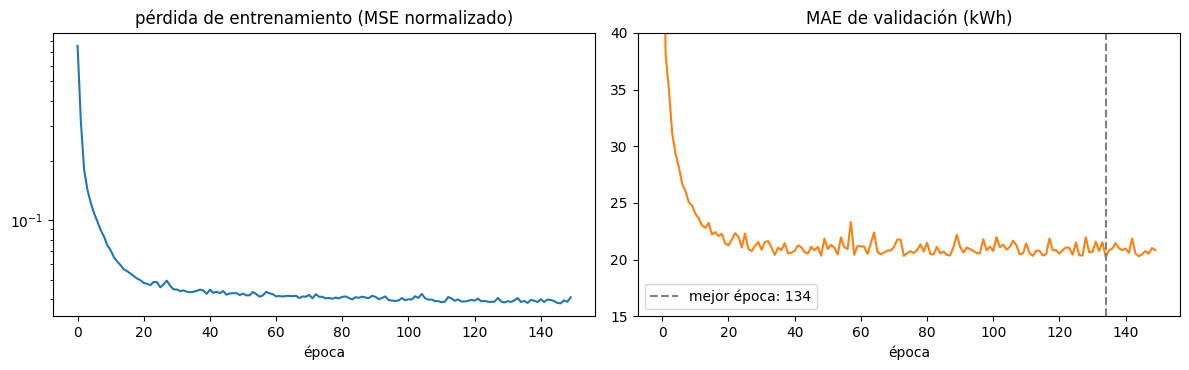

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
ejes[0].plot(historia["perdida"])
ejes[0].set_yscale("log")
ejes[0].set_title("pérdida de entrenamiento (MSE normalizado)")
ejes[1].plot(historia["mae_validacion"], color="tab:orange")
ejes[1].axvline(mejor_epoca, color="gray", linestyle="--", label=f"mejor época: {mejor_epoca}")
ejes[1].set_ylim(15, 40)
ejes[1].set_title("MAE de validación (kWh)")
ejes[1].legend()
for eje in ejes:
    eje.set_xlabel("época")
plt.tight_layout()
plt.show()

La pérdida de entrenamiento cae rápido en las primeras 20 épocas y después casi no se mueve. El MAE de validación sigue el mismo patrón: desde la época 20 oscila entre 20 y 22 kWh sin una tendencia clara. La red ya aprendió lo que los datos permiten, y lo que queda son fluctuaciones de un mini-batch a otro. El menor valor, 20.2 kWh, cayó en la época 134.

Quedarse con el estado de la mejor época, en vez del último, es una protección barata. Aquí casi no cambia nada, pero con más épocas o menos datos la validación puede empezar a empeorar al final (el sobreajuste de `04_ajuste_polinomial_y_sobreajuste`), y entonces el último estado no es el que conviene.

## 9. Guardar el mejor modelo

Guardar solo los pesos no alcanza. Para usar el modelo después hacen falta también la arquitectura, el orden de las columnas de entrada y, sobre todo, **las estadísticas de normalización**: sin ellas no hay forma de preparar una entrada nueva igual que en el entrenamiento. La guía de MLOps de Google pide guardar junto al modelo todo lo necesario para reproducirlo y saber de dónde salió. Lo juntamos en un diccionario y lo guardamos con `torch.save`:

In [12]:
punto_de_control = {
    "version": "consumo-v1",
    "columnas_entrada": COLUMNAS[:4],
    "arquitectura": {"entradas": 4, "ocultas": 64},
    "estadisticas": estadisticas,
    "pesos": mejor_estado,
    "epoca": mejor_epoca,
    "mae_validacion": mejor_mae,
    "version_pytorch": str(torch.__version__),
}

ruta_modelo = CARPETA / "consumo-v1.pt"
torch.save(punto_de_control, ruta_modelo)
print(f"{ruta_modelo.name}: {ruta_modelo.stat().st_size / 1024:.0f} KB")

consumo-v1.pt: 22 KB


## 10. Evaluar una sola vez en la prueba

Con el modelo elegido, por fin miramos la prueba. Cargamos el mejor estado (no el de la última época) y comparamos con las líneas base:

In [13]:
modelo.load_state_dict(mejor_estado)

print(f"{'modelo':18s}   MAE validación   MAE prueba")
for nombre, predecir in lineas_base.items():
    print(f"{nombre:18s} {mae(predecir(X_val), y_val):12.1f} {mae(predecir(X_pru), y_pru):12.1f}")
print(f"{'red neuronal':18s} {mae(predecir_kwh(modelo, X_val, estadisticas), y_val):12.1f} "
      f"{mae(predecir_kwh(modelo, X_pru, estadisticas), y_pru):12.1f}")

piso = 25 * math.sqrt(2 / math.pi)
print(f"\nMAE del ruido de los datos (el mínimo posible): {piso:.1f}")

modelo               MAE validación   MAE prueba
la media                   95.0         98.5
kWh por m²                108.6        117.6
regresión lineal           42.7         46.4
red neuronal               20.2         22.4

MAE del ruido de los datos (el mínimo posible): 19.9


En la prueba, la red se equivoca en 22 kWh por casa: menos de la mitad que la regresión lineal y menos de un cuarto que la media. Los cuatro modelos mantienen su orden de la validación a la prueba, así que la elección no dependió de la suerte del conjunto de validación.

La prueba da algo peor que la validación (22.4 contra 20.2). Es lo esperable: la validación se usó para elegir la época, y lo que se elige mirando un conjunto tiende a verse un poco mejor en ese conjunto. Por eso el número que se informa es el de prueba.

Como los datos son sintéticos, sabemos algo que en un problema real no se sabe: el ruido que agregamos tiene desviación 25 kWh, y su MAE es $25\sqrt{2/\pi} \approx 19.9$ kWh. Ningún modelo puede bajar de ahí, porque ese ruido no depende de las entradas. La red queda a unos 2 kWh de ese piso.

## 11. Analizar los errores

Un solo número no dice **dónde** se equivoca un modelo. Géron recomienda mirar los errores por grupos, y aquí la exploración de la sección 5 sugiere cuáles: rangos de temperatura, con y sin aire acondicionado.

temperatura   aire    casas   MAE lineal   MAE red
  -5 a   5   no        61         52.0      23.4
   5 a  15   no        64         32.9      22.9
  15 a  22   no        46         38.5      20.0
  22 a  28   no        35         28.2      18.0
  28 a  35   no        44         28.6      22.4
  -5 a   5   sí        34         39.1      20.9
   5 a  15   sí        33         57.5      27.8
  15 a  22   sí        26         63.3      22.9
  22 a  28   sí        14         31.2      23.6
  28 a  35   sí        32        107.8      23.3


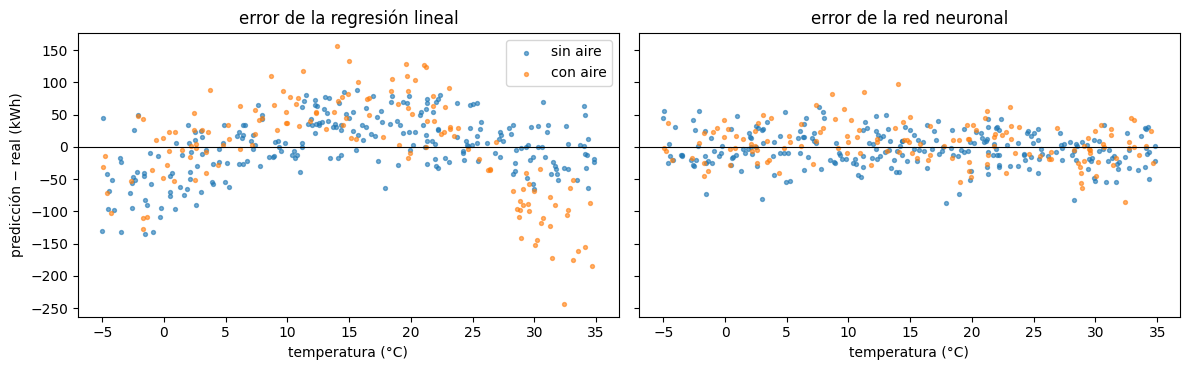

In [14]:
error_lineal = lineas_base["regresión lineal"](X_pru) - y_pru
error_red = predecir_kwh(modelo, X_pru, estadisticas) - y_pru

rangos = [(-5, 5), (5, 15), (15, 22), (22, 28), (28, 35)]
print("temperatura   aire    casas   MAE lineal   MAE red")
for aire in [0, 1]:
    for desde, hasta in rangos:
        grupo = (X_pru[:, 2] >= desde) & (X_pru[:, 2] < hasta) & (X_pru[:, 3] == aire)
        print(f"{desde:4d} a {hasta:3d}   {'sí' if aire else 'no':4s} {grupo.sum().item():7d} "
              f"{error_lineal[grupo].abs().mean():12.1f} {error_red[grupo].abs().mean():9.1f}")

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for eje, error, nombre in zip(ejes, [error_lineal, error_red], ["regresión lineal", "red neuronal"]):
    con_aire = X_pru[:, 3] == 1
    eje.scatter(X_pru[~con_aire, 2], error[~con_aire], s=8, alpha=0.6, label="sin aire")
    eje.scatter(X_pru[con_aire, 2], error[con_aire], s=8, alpha=0.6, label="con aire")
    eje.axhline(0, color="black", linewidth=0.8)
    eje.set_xlabel("temperatura (°C)")
    eje.set_title(f"error de la {nombre}")
ejes[0].set_ylabel("predicción − real (kWh)")
ejes[0].legend()
plt.tight_layout()
plt.show()

La regresión lineal no se equivoca parejo. Sus peores grupos son justamente los extremos de la U: el frío (52 kWh en casas sin aire por debajo de 5 °C) y, sobre todo, el calor en casas con aire acondicionado (108 kWh sobre 28 °C). Una función lineal de la temperatura no puede subir hacia los dos lados, y un solo coeficiente para el aire acondicionado no puede expresar que solo importa cuando hace calor. Por eso sus errores forman una curva en el gráfico: subestima en los extremos y sobreestima en el medio.

Los errores de la red son parejos en todos los grupos, entre 18 y 28 kWh, y en el gráfico forman una nube sin forma alrededor de 0. Esa falta de forma es lo que se busca: lo que queda es ruido que ninguna función de las entradas puede predecir.

## 12. Usar el modelo guardado

Ahora el modelo sale del notebook. Escribimos la función que usaría otro programa: recibe la ruta del archivo y una tabla de casas, y devuelve el consumo estimado. Hace tres cosas, en orden: reconstruye el modelo a partir del punto de control, **valida** las entradas con las mismas reglas que los datos de entrenamiento, y las **normaliza con las estadísticas guardadas**.

In [15]:
def cargar_y_predecir(ruta, casas):
    guardado = torch.load(ruta)
    modelo = ModeloConsumo(**guardado["arquitectura"])
    modelo.load_state_dict(guardado["pesos"])

    validas = validar(casas, guardado["columnas_entrada"])
    if not validas.all():
        raise ValueError(f"{(~validas).sum().item()} casa(s) con datos fuera de las reglas")
    return predecir_kwh(modelo, casas, guardado["estadisticas"])


casas_nuevas = torch.tensor([
    # superficie, personas, temperatura, aire acondicionado
    [80.0, 2, 10.0, 0],
    [180.0, 4, 0.0, 0],
    [180.0, 4, 32.0, 1],
    [180.0, 4, 32.0, 0],
])
for casa, kwh in zip(casas_nuevas, cargar_y_predecir(ruta_modelo, casas_nuevas)):
    print(f"{casa[0]:5.0f} m², {casa[1]:.0f} personas, {casa[2]:4.0f} °C, aire {'sí' if casa[3] else 'no'}:  {kwh:5.0f} kWh")

   80 m², 2 personas,   10 °C, aire no:    215 kWh
  180 m², 4 personas,    0 °C, aire no:    526 kWh
  180 m², 4 personas,   32 °C, aire sí:    539 kWh
  180 m², 4 personas,   32 °C, aire no:    347 kWh


Las dos últimas casas son iguales salvo por el aire acondicionado, y el modelo les asigna consumos muy distintos con 32 °C. Eso no se lo dijo nadie: lo aprendió de los datos.

Si llega una entrada fuera de las reglas, la función se niega a predecir en lugar de devolver un número sin sentido:

In [16]:
try:
    cargar_y_predecir(ruta_modelo, torch.tensor([[120.0, 0, 18.0, 1]]))
except ValueError as error:
    print("ValueError:", error)

  personas               0 faltantes     1 fuera de [1, 12]
ValueError: 1 casa(s) con datos fuera de las reglas


### El error más común al poner un modelo en uso

Las *Rules of Machine Learning* dedican varias reglas al **sesgo entre entrenamiento y servicio** (*training-serving skew*): diferencias entre cómo se preparan los datos al entrenar y cómo se preparan al usar el modelo. El caso más típico es olvidar la normalización. Así se ve:

In [17]:
guardado = torch.load(ruta_modelo)
modelo_cargado = ModeloConsumo(**guardado["arquitectura"])
modelo_cargado.load_state_dict(guardado["pesos"])
modelo_cargado.eval()

with torch.no_grad():
    sin_normalizar = modelo_cargado(casas_nuevas) * guardado["estadisticas"]["desv_y"] + guardado["estadisticas"]["media_y"]
    bien = cargar_y_predecir(ruta_modelo, casas_nuevas)

for casa, mal, ok in zip(casas_nuevas, sin_normalizar, bien):
    print(f"{casa.tolist()}:   sin normalizar {mal:8.0f} kWh   bien {ok:5.0f} kWh")

[80.0, 2.0, 10.0, 0.0]:   sin normalizar     6715 kWh   bien   215 kWh
[180.0, 4.0, 0.0, 0.0]:   sin normalizar    17321 kWh   bien   526 kWh
[180.0, 4.0, 32.0, 1.0]:   sin normalizar    15016 kWh   bien   539 kWh
[180.0, 4.0, 32.0, 0.0]:   sin normalizar    14946 kWh   bien   347 kWh


El modelo no da error: recibe cuatro números y devuelve uno. Pero la red aprendió con entradas normalizadas, donde una casa típica tiene valores entre −2 y 2. Una superficie de 180 sin normalizar es, para ella, una casa 180 desviaciones por encima de la media, y las predicciones salen absurdas. Por eso `cargar_y_predecir` lee las estadísticas del mismo archivo que los pesos: no hay forma de usar unos sin las otras.

## 13. Resumen

El recorrido completo, como lista para el próximo proyecto:

1. **Plantear el problema y la métrica** antes de tocar los datos. Aquí, regresión del consumo con MAE en kWh.
2. **Validar los datos** con reglas que salen del problema, no de los datos. Contar y descartar (o corregir) lo que no las cumple.
3. **Separar entrenamiento, validación y prueba** al principio, con semilla fija. La prueba no se mira hasta el final.
4. **Líneas base primero**: la media, una regla de negocio, un modelo lineal. Son la vara para medir si la red aporta.
5. **`Dataset`, `DataLoader` y `nn.Module`** para organizar datos y modelo. Normalizar con estadísticas del entrenamiento solamente.
6. **Entrenar mirando la validación** y quedarse con el mejor estado, no con el último.
7. **Guardar el punto de control completo**: pesos, arquitectura, columnas, estadísticas de normalización y métricas.
8. **Evaluar una vez en la prueba** y comparar con las líneas base.
9. **Analizar los errores por grupos** para saber dónde falla cada modelo.
10. **Usar el modelo con la misma preparación con que se entrenó**, validando las entradas.

En producción, la guía de MLOps de Google propone automatizar estos pasos (validación, entrenamiento, evaluación, registro de versiones y monitoreo) para que corran solos cada vez que llegan datos nuevos. Aquí los hicimos a mano una vez, que es lo que hay que entender antes de automatizarlos.

## Ejercicios

1. Calcula las estadísticas de normalización con **todos** los datos válidos en vez de solo el entrenamiento, y vuelve a entrenar. ¿Cambia mucho el MAE de prueba? ¿Por qué igual es un error hacerlo?
2. Entrena la regresión lineal de la sección 6 agregando dos características nuevas: $\max(0, 15 - T)$ y $\text{aire} \cdot \max(0, T - 22)$, donde $T$ es la temperatura. ¿Cuánto mejora? ¿Qué dice esto sobre la ventaja de la red en este problema?
3. Agrega una regla de validación que detecte filas duplicadas. ¿Cómo la implementarías con tensores?
4. Cambia la red por una con una sola capa oculta de 16 neuronas. ¿Cuánto empeora en prueba? ¿Sigue superando a la regresión lineal?
5. Agrega al punto de control un campo con el MAE de prueba y otro con la fecha. Luego escribe una función que cargue dos puntos de control y diga cuál es mejor según la validación.